In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv('/content/housing_prices_regression.csv.xls')
df

,num_bedrooms,year_built,zipcode_dup,zipcode,size_sqft,has_garage,id,has_garden,num_bathrooms,sale_price
0,2.0,2021.0,110002.0,110002.0,1075,Ys,H20000,NaN,3.0,NaN
1,3.0,1954.0,560001.0,560001.0,1482,Ye,H20001,o,1.5,293483.53
2,2.0,1991.0,560002.0,560002.0,1689,No,H20002,No,2.5,179736.91
3,3.0,1956.0,NaN,NaN,1415,Yes,H20003,es,NaN,462700.04
4,NaN,1991.0,560001.0,560001.0,1765,No,H20004,NO,1.0,272214.40
...,...,...,...,...,...,...,...,...,...,...
255,2.0,1950.0,110001.0,110001.0,1402,No,H20012,NO,2.0,NaN
256,2.0,1991.0,560002.0,560002.0,1689,No,H20002,No,2.5,179736.91
257,3.0,1954.0,560001.0,560001.0,1482,Ye,H20001,o,1.5,293483.53
258,3.0,1974.0,110003.0,110003.0,1239,YES,NaN,NaN,2.0,701046.18


In [5]:
df.head()

,num_bedrooms,year_built,zipcode_dup,zipcode,size_sqft,has_garage,id,has_garden,num_bathrooms,sale_price
0,2.0,2021.0,110002.0,110002.0,1075,Ys,H20000,NaN,3.0,NaN
1,3.0,1954.0,560001.0,560001.0,1482,Ye,H20001,o,1.5,293483.53
2,2.0,1991.0,560002.0,560002.0,1689,No,H20002,No,2.5,179736.91
3,3.0,1956.0,NaN,NaN,1415,Yes,H20003,es,NaN,462700.04
4,NaN,1991.0,560001.0,560001.0,1765,No,H20004,NO,1.0,272214.40


In [6]:
df.tail()

,num_bedrooms,year_built,zipcode_dup,zipcode,size_sqft,has_garage,id,has_garden,num_bathrooms,sale_price
255,2.0,1950.0,110001.0,110001.0,1402,No,H20012,NO,2.0,NaN
256,2.0,1991.0,560002.0,560002.0,1689,No,H20002,No,2.5,179736.91
257,3.0,1954.0,560001.0,560001.0,1482,Ye,H20001,o,1.5,293483.53
258,3.0,1974.0,110003.0,110003.0,1239,YES,NaN,NaN,2.0,701046.18
259,2.0,1999.0,110002.0,110002.0,1399,NO,H20093,No,2.5,48165.82


### Part 1: Inspecting Missing Values & Column Inconsistencies

In [40]:
print("Dataset Info:")
print(df.info())


Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260 entries, 0 to 259
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   num_bedrooms   238 non-null    float64
 1   year_built     241 non-null    float64
 2   zipcode_dup    230 non-null    float64
 3   zipcode        230 non-null    float64
 4   size_sqft      237 non-null    object 
 5   has_garage     237 non-null    object 
 6   id             230 non-null    object 
 7   has_garden     232 non-null    object 
 8   num_bathrooms  221 non-null    float64
 9   sale_price     238 non-null    float64
dtypes: float64(6), object(4)
memory usage: 20.4+ KB
None


In [ ]:
print("\nMissing values per column:")
print(df.isnull().sum())

### Part 2: Cleaning Inconsistencies & Imputing Null Values

In [12]:
### Clean Data Preprocessing (Replaced by the sequential human-written cells below)

,num_bedrooms,year_built,zipcode,size_sqft,has_garage,id,has_garden,num_bathrooms,sale_price
0,2.0,2021.0,110002.0,1075.0,Yes,H20000,Unknown,3.0,444707.67
1,3.0,1954.0,560001.0,1482.0,Yes,H20001,Yes,1.5,293483.53
2,2.0,1991.0,560002.0,1689.0,No,H20002,No,2.5,179736.91
3,3.0,1956.0,110003.0,1415.0,Yes,H20003,Yes,2.0,462700.04
4,3.0,1991.0,560001.0,1765.0,No,H20004,No,1.0,272214.40


### Step 1: Initialize Clean Dataset and Handle Redundant Columns

In [28]:
df_clean = df.copy()
if df_clean['zipcode'].equals(df_clean['zipcode_dup']):
    df_clean.drop(columns=['zipcode_dup'], inplace=True)
else:
    df_clean['zipcode'] = df_clean['zipcode'].fillna(df_clean['zipcode_dup'])
    df_clean.drop(columns=['zipcode_dup'], inplace=True)

### Step 2: Standardize Categorical Columns

In [29]:
garage_mapping = {'yes': 'Yes', 'ye': 'Yes', 'ys': 'Yes', 'no': 'No'}
df_clean['has_garage'] = df_clean['has_garage'].str.strip().str.lower().map(garage_mapping).fillna('Unknown')
garden_mapping = {'yes': 'Yes', 'ye': 'Yes', 'ys': 'Yes', 'es': 'Yes', 'o': 'Yes', 'no': 'No'}
df_clean['has_garden'] = df_clean['has_garden'].str.strip().str.lower().map(garden_mapping).fillna('Unknown')

### Step 3: Handle Type Conversion

In [30]:
df_clean['size_sqft'] = pd.to_numeric(df_clean['size_sqft'], errors='coerce')

### Step 4: Impute Missing Numeric Values

In [31]:
numeric_features = ['num_bedrooms', 'year_built', 'size_sqft', 'num_bathrooms', 'sale_price', 'zipcode']
for col in numeric_features:
    median_val = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(median_val)

### Step 5: Clean Categorical Identifiers

In [32]:
df_clean['id'] = df_clean['id'].fillna('Unknown')
display(df_clean.head())

,num_bedrooms,year_built,zipcode,size_sqft,has_garage,id,has_garden,num_bathrooms,sale_price
0,2.0,2021.0,110002.0,1075.0,Yes,H20000,Unknown,3.0,444707.67
1,3.0,1954.0,560001.0,1482.0,Yes,H20001,Yes,1.5,293483.53
2,2.0,1991.0,560002.0,1689.0,No,H20002,No,2.5,179736.91
3,3.0,1956.0,110003.0,1415.0,Yes,H20003,Yes,2.0,462700.04
4,3.0,1991.0,560001.0,1765.0,No,H20004,No,1.0,272214.40


In [33]:
df_clean.to_csv('/content/housing_prices_cleaned.csv', index=False)
print("Preprocessed dataset successfully saved to: /content/housing_prices_cleaned.csv")
display(df_clean.info())

Preprocessed dataset successfully saved to: /content/housing_prices_cleaned.csv
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260 entries, 0 to 259
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   num_bedrooms   260 non-null    float64
 1   year_built     260 non-null    float64
 2   zipcode        260 non-null    float64
 3   size_sqft      260 non-null    float64
 4   has_garage     260 non-null    object 
 5   id             260 non-null    object 
 6   has_garden     260 non-null    object 
 7   num_bathrooms  260 non-null    float64
 8   sale_price     260 non-null    float64
dtypes: float64(6), object(3)
memory usage: 18.4+ KB


None

### Part 3: Visualizations (Univariate, Bivariate, and Multivariate)

### Univariate Analysis

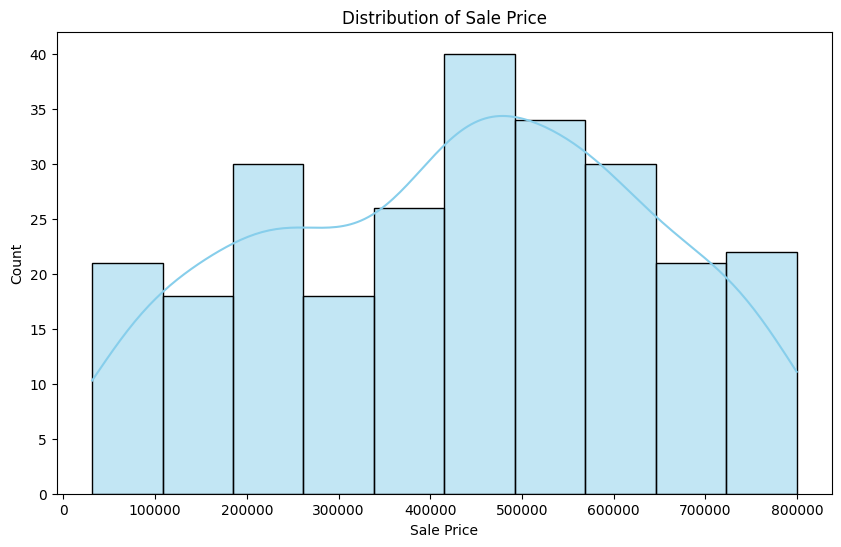

In [34]:
plt.figure(figsize=(10, 6))
sns.histplot(df_clean['sale_price'], kde=True, color='skyblue')
plt.title('Distribution of Sale Price')
plt.xlabel('Sale Price')
plt.ylabel('Count')
plt.show()

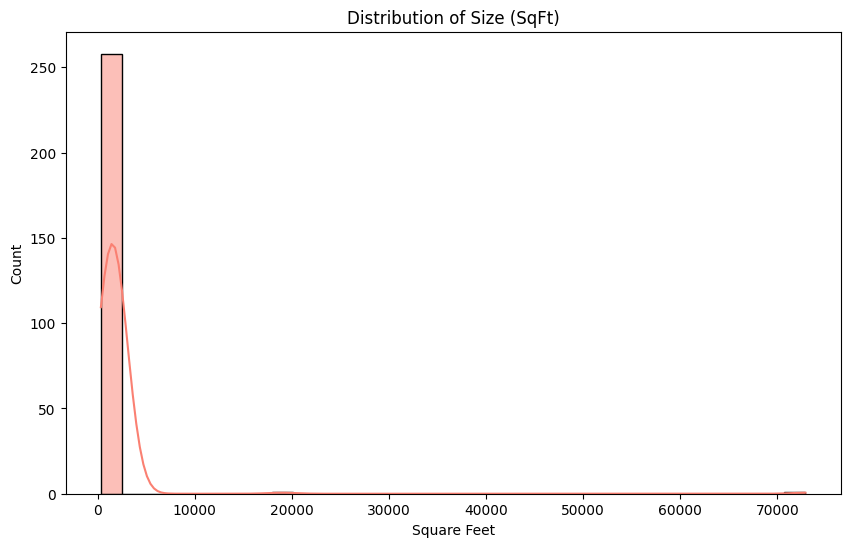

In [35]:
plt.figure(figsize=(10, 6))
sns.histplot(df_clean['size_sqft'], kde=True, color='salmon')
plt.title('Distribution of Size (SqFt)')
plt.xlabel('Square Feet')
plt.ylabel('Count')
plt.show()

### Bivariate Analysis

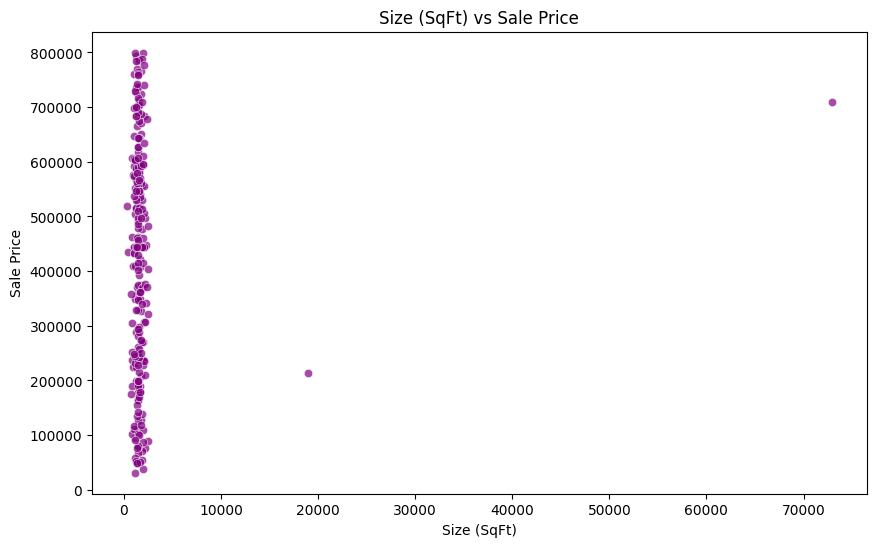

In [36]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_clean, x='size_sqft', y='sale_price', alpha=0.7, color='purple')
plt.title('Size (SqFt) vs Sale Price')
plt.xlabel('Size (SqFt)')
plt.ylabel('Sale Price')
plt.show()

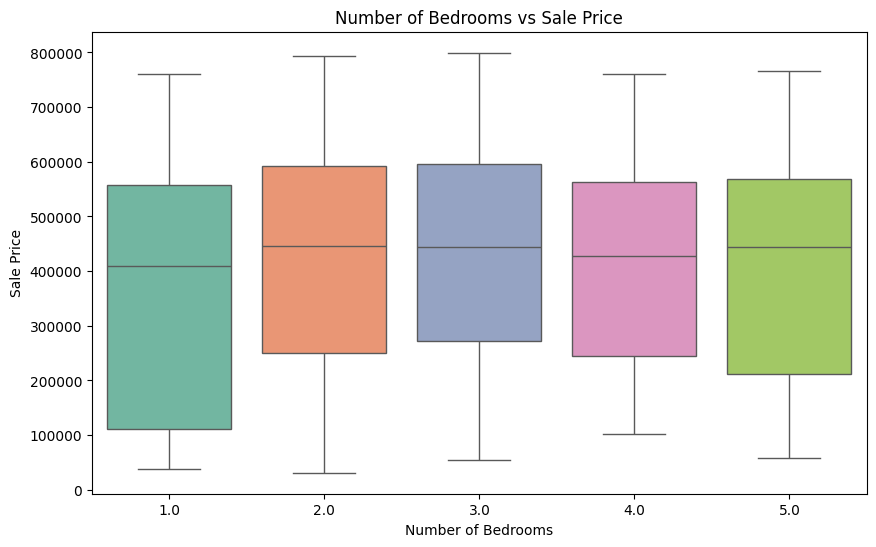

In [37]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_clean, x='num_bedrooms', y='sale_price', hue='num_bedrooms', palette='Set2', legend=False)
plt.title('Number of Bedrooms vs Sale Price')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Sale Price')
plt.show()

### Multivariate Analysis

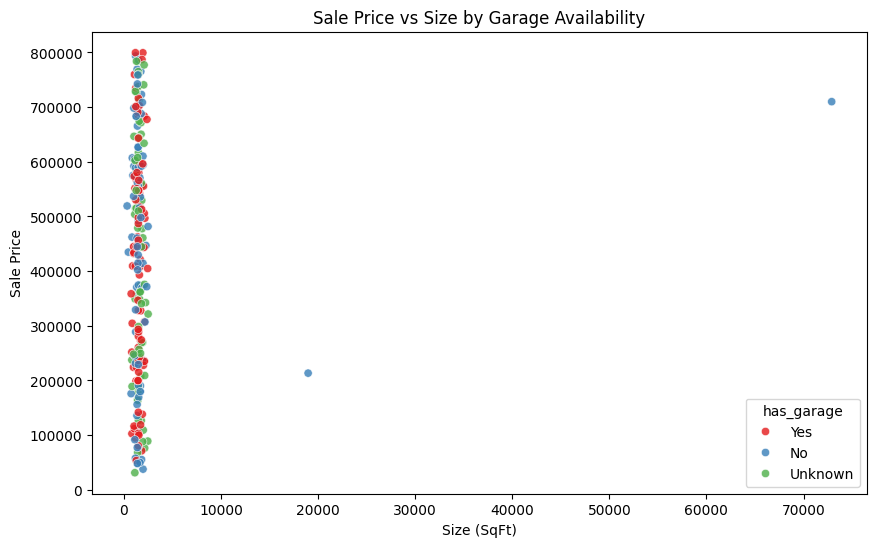

In [38]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_clean, x='size_sqft', y='sale_price', hue='has_garage', palette='Set1', alpha=0.8)
plt.title('Sale Price vs Size by Garage Availability')
plt.xlabel('Size (SqFt)')
plt.ylabel('Sale Price')
plt.show()

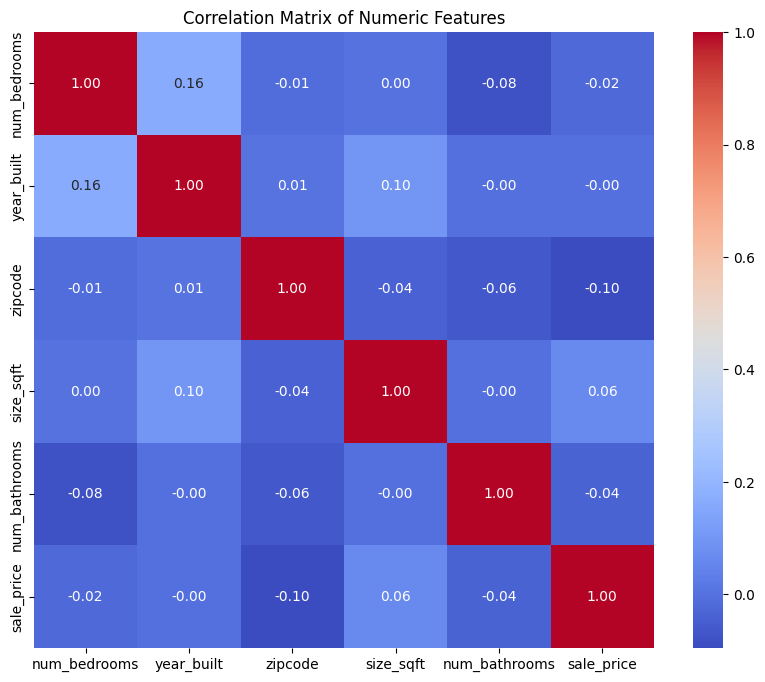

In [39]:
plt.figure(figsize=(10, 8))
numeric_cols = df_clean.select_dtypes(include=[np.number])
sns.heatmap(numeric_cols.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numeric Features')
plt.show()

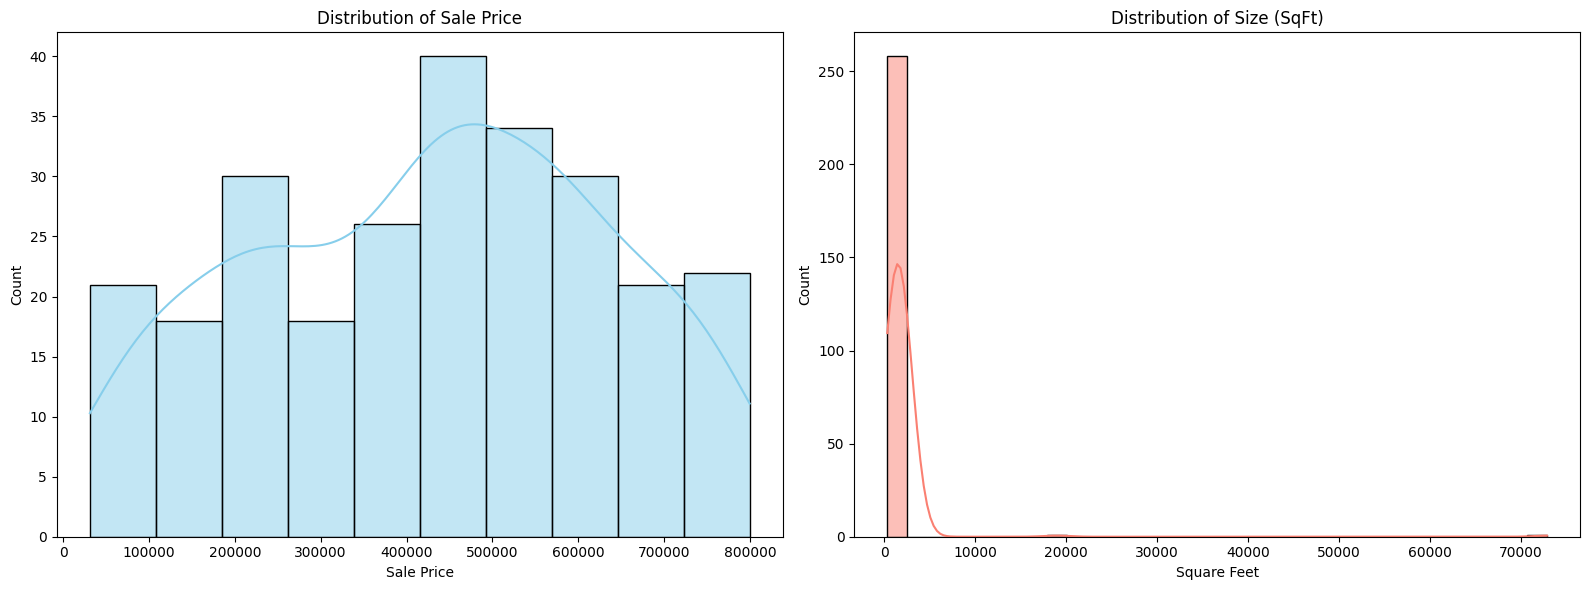

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.histplot(df_clean['sale_price'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Sale Price')
axes[0].set_xlabel('Sale Price')
sns.histplot(df_clean['size_sqft'], kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Distribution of Size (SqFt)')
axes[1].set_xlabel('Square Feet')
plt.tight_layout()
plt.show()

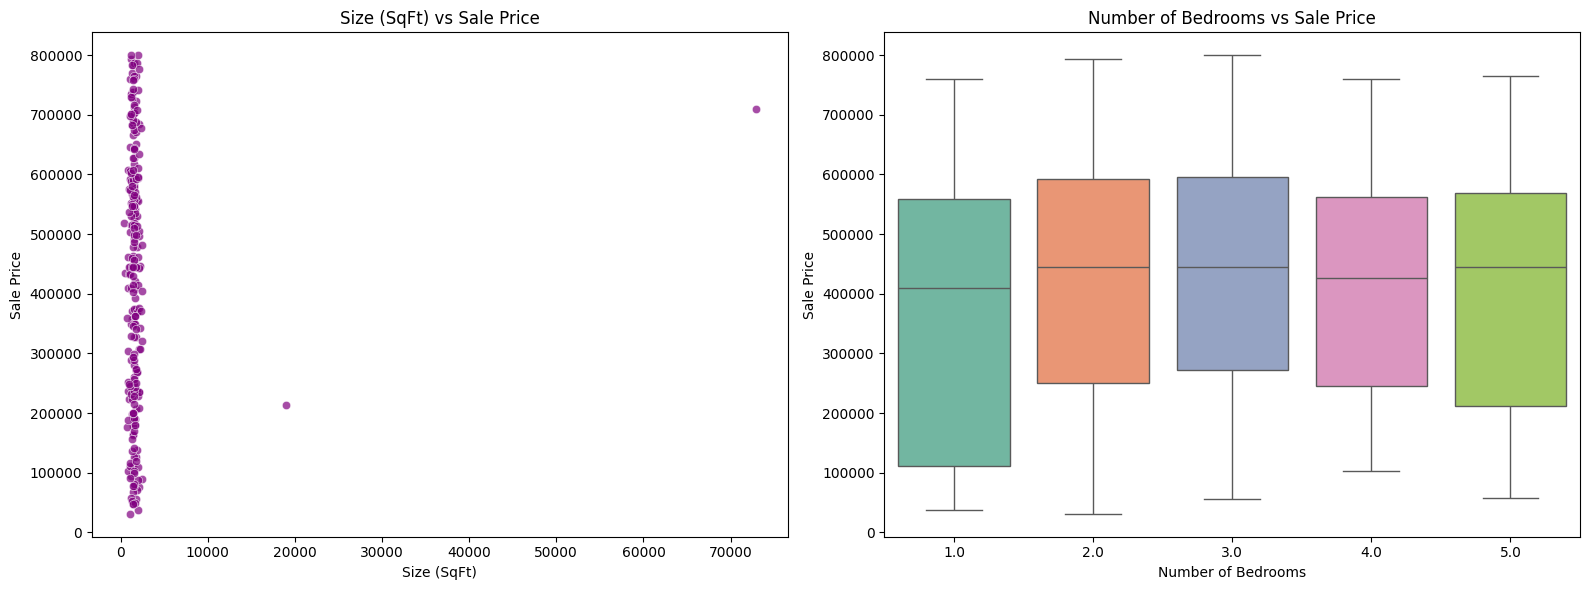

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(data=df_clean, x='size_sqft', y='sale_price', ax=axes[0], alpha=0.7, color='purple')
axes[0].set_title('Size (SqFt) vs Sale Price')
axes[0].set_xlabel('Size (SqFt)')
axes[0].set_ylabel('Sale Price')
sns.boxplot(data=df_clean, x='num_bedrooms', y='sale_price', ax=axes[1], hue='num_bedrooms', palette='Set2', legend=False)
axes[1].set_title('Number of Bedrooms vs Sale Price')
axes[1].set_xlabel('Number of Bedrooms')
axes[1].set_ylabel('Sale Price')
plt.tight_layout()
plt.show()

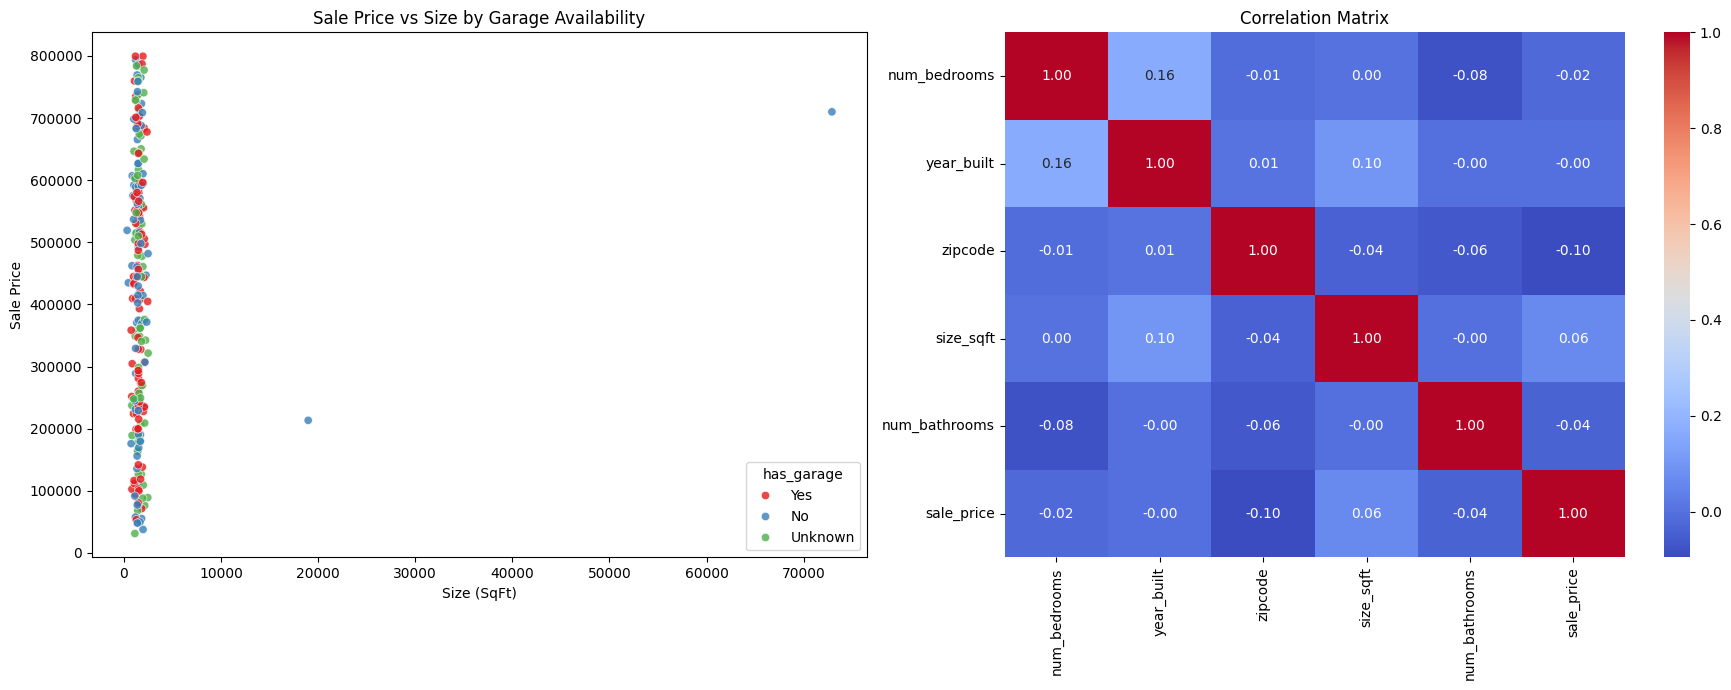

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sns.scatterplot(data=df_clean, x='size_sqft', y='sale_price', hue='has_garage', palette='Set1', alpha=0.8, ax=axes[0])
axes[0].set_title('Sale Price vs Size by Garage Availability')
axes[0].set_xlabel('Size (SqFt)')
axes[0].set_ylabel('Sale Price')
numeric_cols = df_clean.select_dtypes(include=[np.number])
sns.heatmap(numeric_cols.corr(), annot=True, cmap='coolwarm', fmt='.2f', ax=axes[1])
axes[1].set_title('Correlation Matrix')
plt.tight_layout()
plt.show()